In [11]:
# Pick up edits to `.py` files without restarting kernel
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [12]:
# Import libraries
import cv2 as cv
import numpy as np

In [13]:
# Import modules
import config
from pipeline import (
    build_detector,
    build_filter,
    build_matcher,
    extract_features,
    filter_matches,
    match_descriptors,
)
from utils import (
    center_crop_to_size,
    grab_frame,
    load_image,
    plot_image,
    plot_keypoints,
    plot_matches,
    shrink_to_max_side,
)

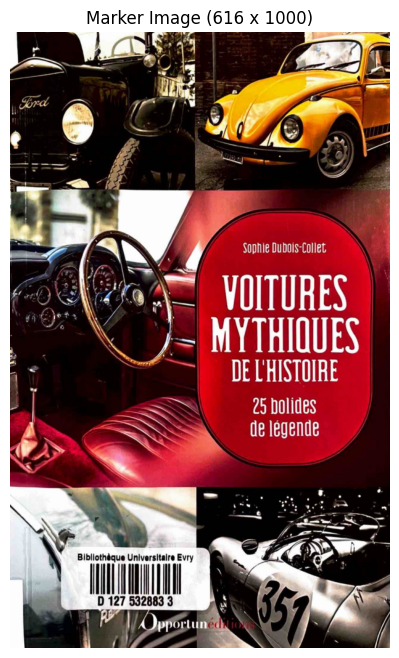

In [14]:
# Marker image
marker = load_image(config.MARKER_PATH)
marker = shrink_to_max_side(marker, config.MARKER_MAX_SIDE)
plot_image(marker, f"Marker Image ({marker.shape[1]} x {marker.shape[0]})")

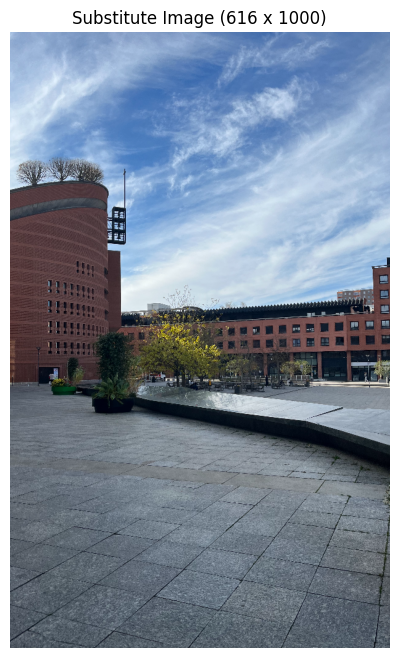

In [15]:
# Substitute image
substitute = load_image(config.SUBSTITUTE_PATH)
substitute = center_crop_to_size(substitute, marker.shape[1], marker.shape[0])
plot_image(
    substitute, f"Substitute Image ({substitute.shape[1]} x {substitute.shape[0]})"
)

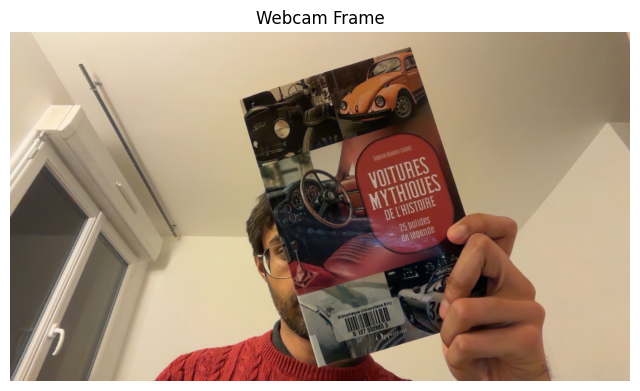

In [16]:
# Camera frame
if config.CAPTURE_NEW_FRAME:
    cv.imwrite(config.FRAME_PATH, grab_frame(config.CAMERA_INDEX))
frame = load_image(config.FRAME_PATH)
plot_image(frame, "Webcam Frame")

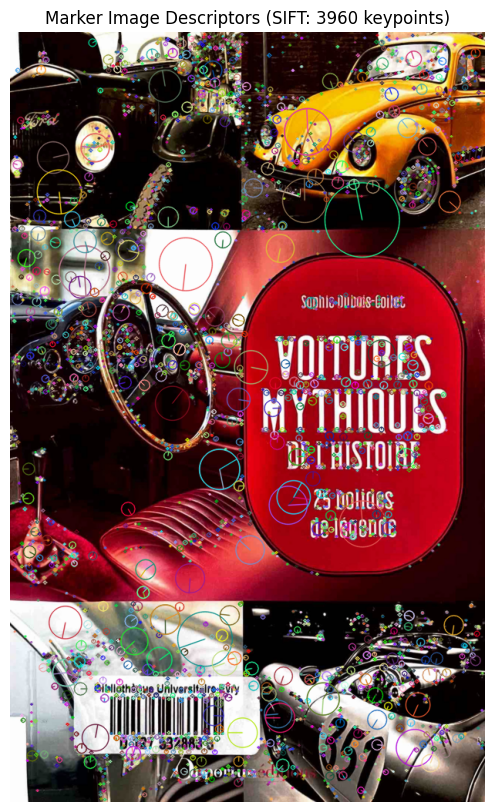

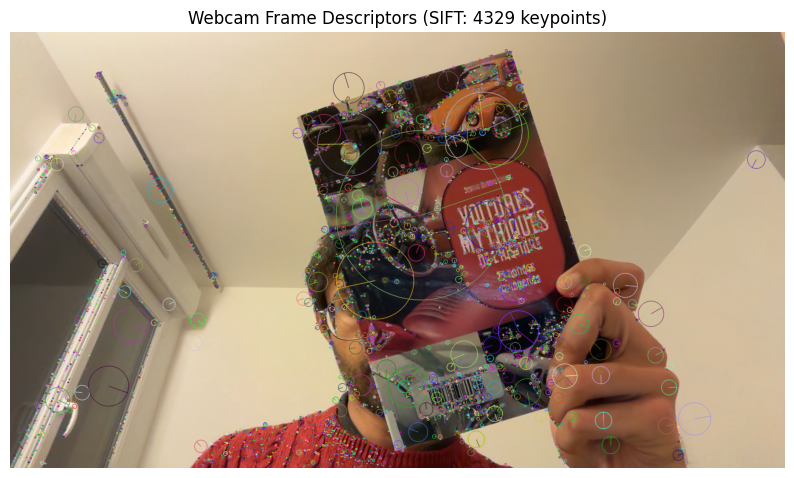

In [17]:
# Image descriptor extraction
detector = build_detector(config.DETECTOR_NAME)

# Marker keypoints
marker_keypoints, marker_descriptors = extract_features(detector, marker)
plot_keypoints(
    marker,
    marker_keypoints,
    f"Marker Image Descriptors ({config.DETECTOR_NAME}: {len(marker_keypoints)} keypoints)",
    10,
)

# Frame keypoints
frame_keypoints, frame_descriptors = extract_features(detector, frame)
plot_keypoints(
    frame,
    frame_keypoints,
    f"Webcam Frame Descriptors ({config.DETECTOR_NAME}: {len(frame_keypoints)} keypoints)",
    10,
)

3960 marker descriptors matched


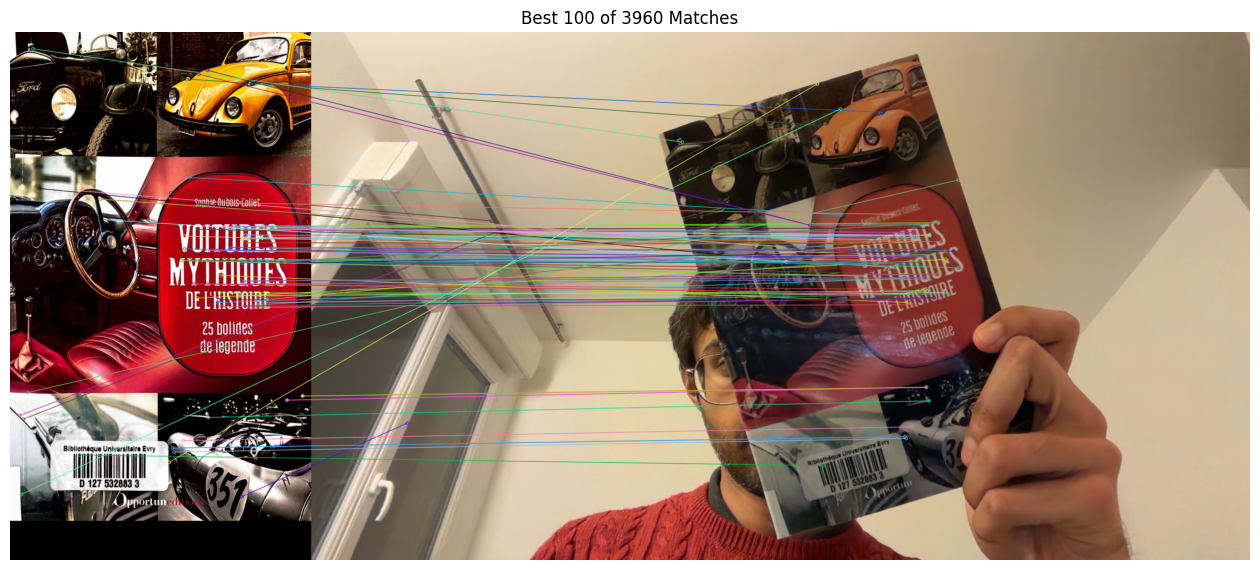

In [18]:
# Descriptor matching
matcher = build_matcher(config.MATCHER_NAME, config.DETECTOR_NAME)
knn_matches = match_descriptors(matcher, marker_descriptors, frame_descriptors)
print(f"{len(knn_matches)} marker descriptors matched")

# Best candidate for each keypoint
best_matches = []
for candidates in knn_matches:
    if candidates:
        best_matches.append(candidates[0])

# Sort by distance
best_matches.sort(key=lambda match: match.distance)

# Plot only the closest matches
shown_match_count = 100
plot_matches(
    marker,
    marker_keypoints,
    frame,
    frame_keypoints,
    best_matches[:shown_match_count],
    f"Best {shown_match_count} of {len(best_matches)} Matches",
)

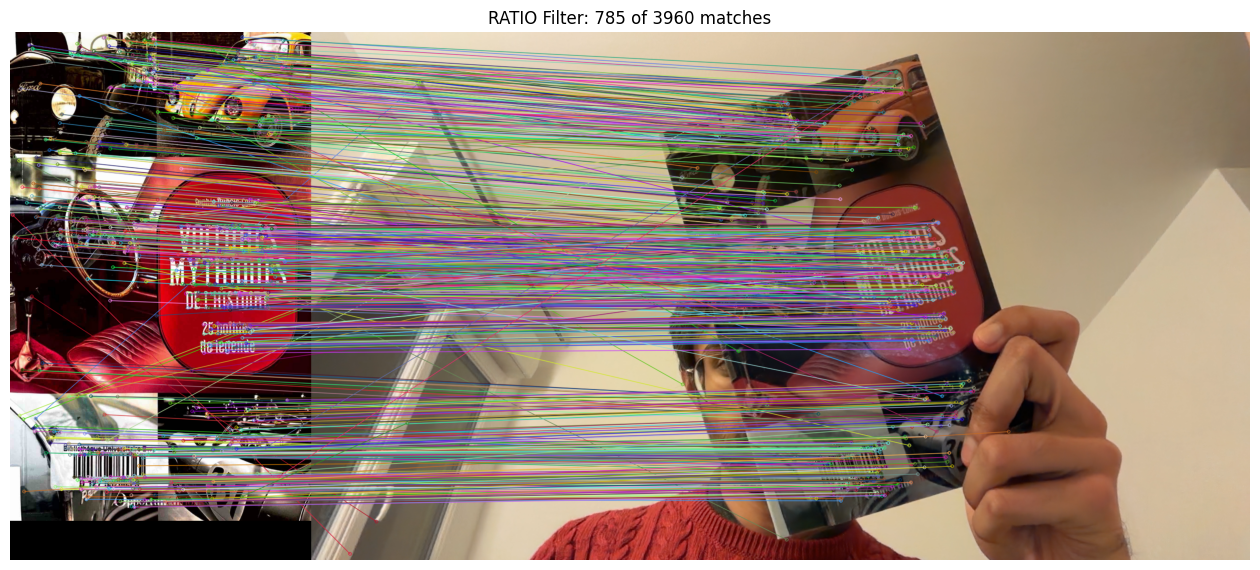

In [19]:
# Match filtering
match_filter = build_filter(config.FILTER_NAME)
good_matches = filter_matches(match_filter, knn_matches)
plot_matches(
    marker,
    marker_keypoints,
    frame,
    frame_keypoints,
    good_matches,
    f"{config.FILTER_NAME} Filter: {len(good_matches)} of {len(knn_matches)} matches",
)

In [20]:
# Homography estimation
# A homography has 8 unknowns and each match gives 2 equations
min_match_count = 4
if len(good_matches) < min_match_count:
    raise RuntimeError(
        f"Homography needs {min_match_count} matches, got {len(good_matches)}"
    )

marker_points = []
frame_points = []
for match in good_matches:
    marker_points.append(marker_keypoints[match.queryIdx].pt)
    frame_points.append(frame_keypoints[match.trainIdx].pt)

marker_points = np.float32(marker_points)
frame_points = np.float32(frame_points)

homography, inlier_mask = cv.findHomography(marker_points, frame_points, cv.RANSAC, 3.0)
if homography is None:
    raise RuntimeError("No homography fits the matches")

inlier_count = int(inlier_mask.sum())
print(f"{inlier_count} of {len(good_matches)} matches are inliers")
print(homography)

520 of 785 matches are inliers
[[ 8.39145972e-01  2.28369891e-01  7.10008733e+02]
 [-2.77158276e-01  8.09227709e-01  2.08846568e+02]
 [-2.84423407e-05 -1.71958047e-05  1.00000000e+00]]
